# 01 Reliability: When Cronbach's Alpha Misleads

**Setting:** a six-item employee engagement scale (people analytics).
**Methods:** Cronbach's alpha, McDonald's omega (from a one-factor CFA),
omega with modeled error covariances, item diagnostics, bootstrap CIs.
**Ground truth:** the data come from a factor model with known loadings
and error variances, so the true reliability of the sum score is known
exactly: the share of its variance that comes from the common factor.

Alpha is the default reliability number in almost every survey report.
It equals the true reliability only under two assumptions: every item
loads equally on the trait (tau-equivalence), and item errors are
uncorrelated. This notebook breaks each assumption in turn and shows
which estimator still lands on the truth.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
_root = pathlib.Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root / "src"))
FIG_DIR = _root / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
# Categorical slots (validated palette), plus ink for the known truth
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#8a8984"

In [2]:
from surveyhub.simulate import simulate_factor_data, true_composite_reliability
from surveyhub.reliability import (cronbach_alpha, alpha_from_cov, omega,
                                   item_total, alpha_if_deleted, bootstrap_ci)

## 1. Three versions of the same scale

* **Equal loadings.** Six items that measure engagement equally well.
* **Unequal loadings.** Two excellent items, two good ones, and two weak
  ones (a common outcome when items are written by committee).
* **Correlated errors.** Equal loadings, but two pairs of items share
  wording ("I feel energized at work" / "I feel energized by my work"),
  so their errors correlate. That shared variance is not engagement.

For each, compare the population value of alpha (computed from the true
covariance matrix, so no sampling noise) with the true reliability.

In [3]:
lam_eq = np.full((6, 1), 0.7)
lam_un = np.array([.9, .85, .75, .55, .4, .3])[:, None]
lam_ce = np.full((6, 1), 0.6)
theta_ce = np.diag(np.full(6, 0.64))
theta_ce[0, 1] = theta_ce[1, 0] = 0.3
theta_ce[2, 3] = theta_ce[3, 2] = 0.3

scenarios = {
    "Equal loadings":    dict(Lambda=lam_eq, Theta=np.diag(1 - lam_eq[:, 0] ** 2), error_cov=[]),
    "Unequal loadings":  dict(Lambda=lam_un, Theta=np.diag(1 - lam_un[:, 0] ** 2), error_cov=[]),
    "Correlated errors": dict(Lambda=lam_ce, Theta=theta_ce, error_cov=[(0, 1), (2, 3)]),
}
print(f"{'scenario':<20s} {'true reliability':>17s} {'population alpha':>17s} {'alpha bias':>11s}")
for name, s in scenarios.items():
    Sigma = s["Lambda"] @ s["Lambda"].T + s["Theta"]
    s["truth"] = true_composite_reliability(s["Lambda"], None, s["Theta"])
    a = alpha_from_cov(Sigma)
    print(f"{name:<20s} {s['truth']:17.3f} {a:17.3f} {a - s['truth']:+11.3f}")

scenario              true reliability  population alpha  alpha bias
Equal loadings                   0.852             0.852      -0.000
Unequal loadings                 0.807             0.787      -0.021
Correlated errors                0.720             0.800      +0.080


With infinite data, alpha is exact in the first case, too low in the
second (it treats the weak items as if they were as good as the strong
ones), and too high in the third (it counts the shared wording as
engagement). The direction of the error depends on which assumption
fails, so a high alpha is not reassuring on its own.

## 2. Sampling distributions at a realistic sample size

Draw 300 surveys of 400 employees from each scenario and compute alpha,
omega from a one-factor CFA, and omega from a CFA that also models the
correlated error pairs.

In [4]:
R, n = 300, 400
rng = np.random.default_rng(1)
results = {}
for name, s in scenarios.items():
    rows = []
    for r in range(R):
        d = simulate_factor_data(n, s["Lambda"], Theta=s["Theta"], seed=rng.integers(1 << 31))
        a = cronbach_alpha(d.X)
        om = omega(d.X).omega
        om_ce = omega(d.X, error_cov=s["error_cov"]).omega if s["error_cov"] else om
        rows.append((a, om, om_ce))
    results[name] = np.array(rows)

labels = ["alpha", "omega", "omega + error cov"]
print(f"{'scenario':<20s} {'estimator':<18s} {'mean':>7s} {'bias':>7s} {'RMSE':>7s}")
for name, s in scenarios.items():
    for k, lab in enumerate(labels):
        est = results[name][:, k]
        print(f"{name:<20s} {lab:<18s} {est.mean():7.3f} {est.mean() - s['truth']:+7.3f} "
              f"{np.sqrt(np.mean((est - s['truth']) ** 2)):7.3f}")
    print()

scenario             estimator             mean    bias    RMSE
Equal loadings       alpha                0.851  -0.001   0.012
Equal loadings       omega                0.852  -0.000   0.012
Equal loadings       omega + error cov    0.852  -0.000   0.012

Unequal loadings     alpha                0.786  -0.021   0.027
Unequal loadings     omega                0.808  +0.000   0.015
Unequal loadings     omega + error cov    0.808  +0.000   0.015

Correlated errors    alpha                0.799  +0.079   0.081
Correlated errors    omega                0.799  +0.079   0.081
Correlated errors    omega + error cov    0.719  -0.001   0.024



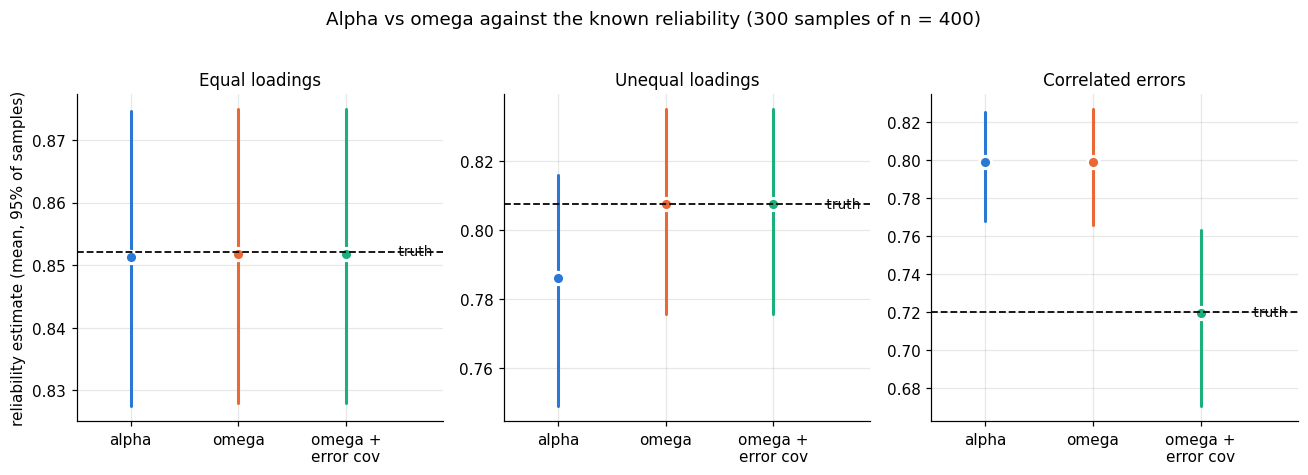

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=False)
colors = [BLUE, ORANGE, AQUA]
for ax, (name, s) in zip(axes, scenarios.items()):
    est = results[name]
    for k, lab in enumerate(labels):
        lo, mid, hi = np.percentile(est[:, k], [2.5, 50, 97.5])
        ax.plot([k, k], [lo, hi], color=colors[k], lw=2, solid_capstyle="round")
        ax.plot(k, est[:, k].mean(), "o", color=colors[k], ms=8,
                markeredgecolor="white", markeredgewidth=2)
    ax.axhline(s["truth"], color=INK, ls="--", lw=1.2)
    ax.text(2.45, s["truth"], " truth", va="center", color=INK, fontsize=9)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["alpha", "omega", "omega +\nerror cov"])
    ax.set_xlim(-0.5, 2.9)
    ax.set_title(name, fontsize=11)
axes[0].set_ylabel("reliability estimate (mean, 95% of samples)")
fig.suptitle("Alpha vs omega against the known reliability (300 samples of n = 400)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "reliability_alpha_omega.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Item diagnostics on one sample

The classic item table: corrected item-total correlations and alpha if
the item is deleted. In the unequal-loadings scale the weak items show
up clearly. A bootstrap CI conveys how precise the reliability estimate
is with 400 respondents.

In [6]:
s = scenarios["Unequal loadings"]
d = simulate_factor_data(400, s["Lambda"], Theta=s["Theta"], seed=7)
it = item_total(d.X)
aid = alpha_if_deleted(d.X)
print(f"alpha (all six items) = {cronbach_alpha(d.X):.3f}\n")
print(f"{'item':<6s} {'true loading':>13s} {'item-total r':>13s} {'alpha if deleted':>17s}")
for j in range(6):
    print(f"Q{j + 1:<5d} {s['Lambda'][j, 0]:13.2f} {it[j]:13.3f} {aid[j]:17.3f}")

est, lo, hi = bootstrap_ci(lambda X: omega(X).omega, d.X, n_boot=500, seed=3)
print(f"\nomega = {est:.3f}, 95% bootstrap CI [{lo:.3f}, {hi:.3f}]  (truth {s['truth']:.3f})")

alpha (all six items) = 0.768

item    true loading  item-total r  alpha if deleted
Q1              0.90         0.732             0.674
Q2              0.85         0.709             0.680
Q3              0.75         0.655             0.695
Q4              0.55         0.494             0.738
Q5              0.40         0.279             0.791
Q6              0.30         0.255             0.796

omega = 0.793, 95% bootstrap CI [0.761, 0.820]  (truth 0.807)


## Takeaways

* Alpha is a lower bound on reliability when loadings differ and an
  upper bound when errors correlate. Real scales usually have both
  problems, so its error can go either way.
* Omega from a one-factor CFA recovers the truth when loadings differ.
  When errors correlate it is only right if the error covariances are
  modeled, which takes substantive knowledge of the items (shared
  wording, shared stems, reversed items).
* Report omega with a bootstrap CI, and check the one-factor model's fit
  before trusting any single reliability number.